In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_defenders = pd.read_excel(r'C:\Users\User\Desktop\Артур\Artur\Защитники\Moneyball_Салават_Юлаев.xlsx', sheet_name='Защитники')

In [2]:
df_defenders.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Игрок       9 non-null      str    
 1   Игр         9 non-null      int64  
 2   Шайбы       9 non-null      int64  
 3   Передачи    9 non-null      int64  
 4   Очки        9 non-null      int64  
 5   Плюс-минус  9 non-null      int64  
 6   Плюс        9 non-null      int64  
 7   Минус       9 non-null      int64  
 8   Штр         9 non-null      int64  
 9   Ш_5х5       9 non-null      int64  
 10  Ш_ПП        9 non-null      int64  
 11  Бр          9 non-null      int64  
 12  %Реал_Бр    9 non-null      float64
 13  БВ/И        9 non-null      float64
 14  ВП/И        9 non-null      float64
 15  См/И        9 non-null      float64
 16  ВПР/И       9 non-null      float64
 17  СмР/И       9 non-null      float64
 18  СПр         9 non-null      int64  
 19  БлБ         9 non-null      int64  
dtypes: 

In [3]:
df_defenders.head()

,Игрок,Игр,Шайбы,Передачи,Очки,Плюс-минус,Плюс,Минус,Штр,Ш_5х5,Ш_ПП,Бр,%Реал_Бр,БВ/И,ВП/И,См/И,ВПР/И,СмР/И,СПр,БлБ
0,Стюарт,54,1,21,22,2,29,27,34,1,0,65,0.015385,1.203704,17.27,20.6,13.22,18.50,14,88
1,Цулыгин,65,4,10,14,-6,36,42,28,4,4,121,0.033058,1.861538,16.67,19.6,14.22,18.42,77,54
2,Кулик,58,2,11,13,5,33,28,20,2,2,44,0.045455,0.758621,14.50,19.4,12.00,17.50,32,66
3,Панин,67,4,6,10,11,37,26,49,4,4,46,0.086957,0.686567,15.78,18.6,14.00,17.22,115,72
4,Зоркин,54,5,4,9,6,34,28,22,4,4,70,0.071429,1.296296,16.98,21.8,14.56,20.17,80,103


In [4]:
df_budget = pd.read_excel(r'C:\Users\User\Desktop\Артур\Artur\Защитники\Moneyball_Салават_Юлаев.xlsx', sheet_name='Бюджет')
df_budget

,Игрок,Зарплата
0,Ремпал,100
1,Василевский,40
2,Ефремов,35
3,Родуолд,30
4,Стюарт,30
5,Броссо,29
6,Зоркин,24
7,Алалыкин,20
8,Сучков,15
9,Кулик,12


In [5]:
df_final = pd.merge(df_defenders, df_budget, on='Игрок', how='left')
df_final

,Игрок,Игр,Шайбы,Передачи,Очки,Плюс-минус,Плюс,Минус,Штр,Ш_5х5,...,Бр,%Реал_Бр,БВ/И,ВП/И,См/И,ВПР/И,СмР/И,СПр,БлБ,Зарплата
0,Стюарт,54,1,21,22,2,29,27,34,1,...,65,0.015385,1.203704,17.27,20.6,13.22,18.50,14,88,30
1,Цулыгин,65,4,10,14,-6,36,42,28,4,...,121,0.033058,1.861538,16.67,19.6,14.22,18.42,77,54,4
2,Кулик,58,2,11,13,5,33,28,20,2,...,44,0.045455,0.758621,14.50,19.4,12.00,17.50,32,66,12
3,Панин,67,4,6,10,11,37,26,49,4,...,46,0.086957,0.686567,15.78,18.6,14.00,17.22,115,72,10
4,Зоркин,54,5,4,9,6,34,28,22,4,...,70,0.071429,1.296296,16.98,21.8,14.56,20.17,80,103,24
5,Василевский,50,3,4,7,0,27,27,18,3,...,51,0.058824,1.020000,15.33,19.2,12.98,17.38,57,149,40
6,Варлов,58,1,4,5,9,28,19,8,1,...,45,0.022222,0.775862,14.17,18.0,12.22,16.45,136,72,6
7,Комаров,48,0,3,3,-8,13,21,24,0,...,32,0.000000,0.666667,12.70,16.7,10.96,15.06,42,48,5
8,Газимов,28,2,0,2,-12,6,18,8,2,...,20,0.100000,0.714286,12.68,16.8,11.11,15.29,14,31,8


In [6]:
df_final['Стоимость блока'] = (df_final['Зарплата'] / df_final['БлБ']).round(2)
df_final['Индекс надежности'] = (df_final['Плюс-минус'] / (df_final['Зарплата'])/10).round(2)
df_final

,Игрок,Игр,Шайбы,Передачи,Очки,Плюс-минус,Плюс,Минус,Штр,Ш_5х5,...,БВ/И,ВП/И,См/И,ВПР/И,СмР/И,СПр,БлБ,Зарплата,Стоимость блока,Индекс надежности
0,Стюарт,54,1,21,22,2,29,27,34,1,...,1.203704,17.27,20.6,13.22,18.50,14,88,30,0.34,0.01
1,Цулыгин,65,4,10,14,-6,36,42,28,4,...,1.861538,16.67,19.6,14.22,18.42,77,54,4,0.07,-0.15
2,Кулик,58,2,11,13,5,33,28,20,2,...,0.758621,14.50,19.4,12.00,17.50,32,66,12,0.18,0.04
3,Панин,67,4,6,10,11,37,26,49,4,...,0.686567,15.78,18.6,14.00,17.22,115,72,10,0.14,0.11
4,Зоркин,54,5,4,9,6,34,28,22,4,...,1.296296,16.98,21.8,14.56,20.17,80,103,24,0.23,0.02
5,Василевский,50,3,4,7,0,27,27,18,3,...,1.020000,15.33,19.2,12.98,17.38,57,149,40,0.27,0.00
6,Варлов,58,1,4,5,9,28,19,8,1,...,0.775862,14.17,18.0,12.22,16.45,136,72,6,0.08,0.15
7,Комаров,48,0,3,3,-8,13,21,24,0,...,0.666667,12.70,16.7,10.96,15.06,42,48,5,0.10,-0.16
8,Газимов,28,2,0,2,-12,6,18,8,2,...,0.714286,12.68,16.8,11.11,15.29,14,31,8,0.26,-0.15


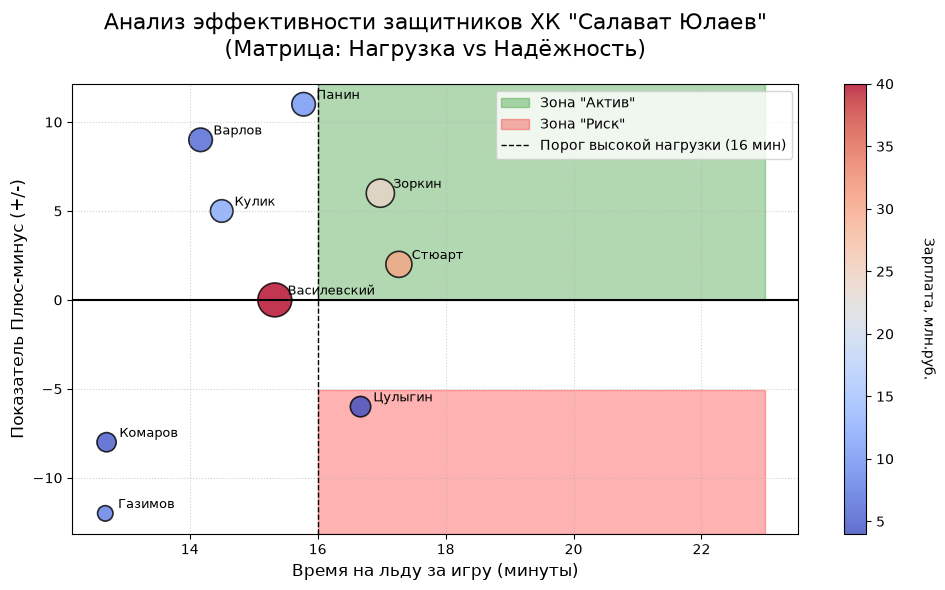

In [ ]:
plt.figure(figsize=(10, 6))

# Зона "Актив" (Зеленый)
plt.axvspan(16, 23, ymin=0.52, ymax=1, color='green', alpha=0.3, label='Зона "Актив"')
# Зона "Риск" (Красный)
plt.axvspan(16, 23, ymin=0, ymax=0.32, color='red', alpha=0.3, label='Зона "Риск"')

# отобразим точки на графике
scatter = plt.scatter(
    df_final['ВП/И'], 
    df_final['Плюс-минус'], 
    s=df_final['БлБ']*4,
    c=df_final['Зарплата'], 
    cmap='coolwarm', 
    alpha=0.8, 
    edgecolors='black', 
    linewidth=1.2
)

# подпишем точки 
for i, row in df_final.iterrows():
    # Сдвигаем текст чуть в сторону, чтобы не накладывался на точку
    plt.text(row['ВП/И'] + 0.2, row['Плюс-минус'] + 0.3, row['Игрок'], fontsize=9, ha='left')

plt.title('Анализ эффективности защитников ХК "Салават Юлаев"\n(Матрица: Нагрузка vs Надёжность)', fontsize=16)
plt.xlabel('Время на льду за игру (минуты)', fontsize=12)
plt.ylabel('Показатель Плюс-минус (+/-)', fontsize=12)
plt.axhline(0, color='black', linewidth=1.5)
plt.axvline(16, color='black', linestyle='--', linewidth=1, label='Порог высокой нагрузки (16 мин)')
plt.grid(True, linestyle=':', alpha=0.6)

# цветовая шкала
сbar = plt.colorbar(scatter)
сbar.set_label('Зарплата, млн.руб.', rotation=270, labelpad=30)
plt.legend()

plt.tight_layout()
plt.show()


# Оценка полезности игры с уровнем зарплаты по игрокам

- Зоркин и Стюарт формируют надежный костяк защиты, сочетая высокую нагрузку с положительной полезностью и адекватной стоимостью контрактов.
Рабочие лошадки. Много играют, приносят пользу, стоят адекватно за свою стоимость.


- Цулыгин. Мало стоит. Получает много игрового времени, но имеет отрицательный показатель полезности (-6). Тактический риск. В игрока верят, но пока он не оправдывает надежд.


- Панин, Варлов, Кулик. Высокая полезность (+/-) при низкой зарплате и большим временем на льду.


- Василевский. Самый дорогий защитник команды. Имеет показатель полезности 0. Играет выше среднего по времени. Стабильный игрок обороны. Он не делает чудес, но и не проваливается. Если цель — не рисковать, он нужен.


- Комаров, Газимов - мало стоят, мало игрового времени и отрицательный показатель полезности.
--------------------------------------
- Зоркин, Стюарт - ключевые игроки защиты с хорошим показателем полезности с сочетанием высокой нагрузки

- Панин - самый эффективный актив. +11 с высоким показателем времени на льду при 10 млн. контракта.

- Цулыгин - новичок, которому доверяют, но пока что он не оправдывает результата. 
    В качестве дальнейших действий по игроку: "разбор полетов", психологический тренинг, дополнительная работа на льду, консультации, тренировки. Давать шансы и смотреть на обратную связь и действия игрока.

- Василевский - большой контракт при нейтральном показатели полезности.

- Комаров, Газимов - игроки ротации. Выпускать в качестве замены.

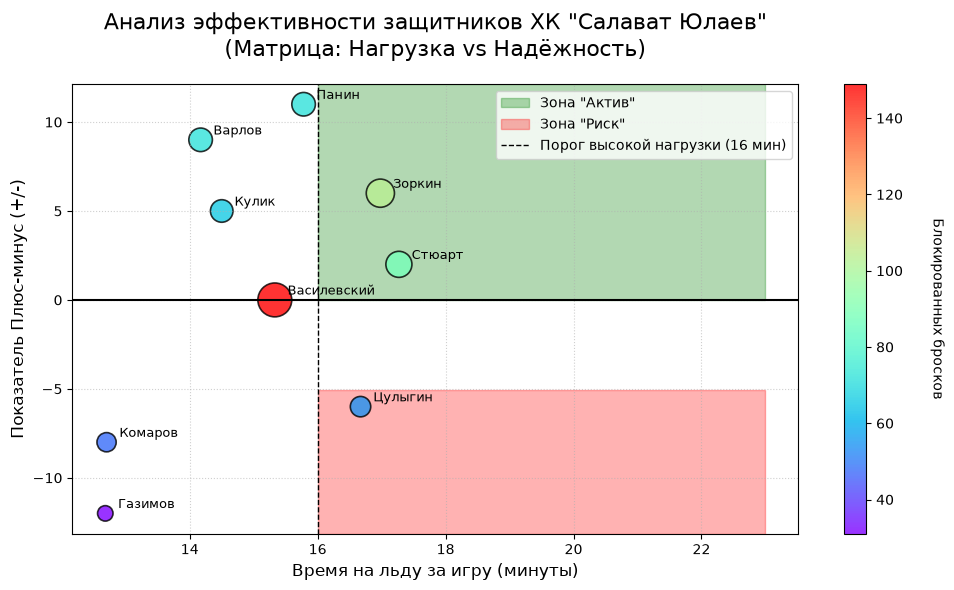

In [ ]:
plt.figure(figsize=(10, 6))

# Зона "Актив" (Зеленый): Высокая нагрузка (>16 мин) и хороший результат (+/- > 0)
plt.axvspan(16, 23, ymin=0.52, ymax=1, color='green', alpha=0.3, label='Зона "Актив"')
# Зона "Риск" (Красный): Высокая нагрузка (>16 мин), но плохой результат (+/- < 0)
plt.axvspan(16, 23, ymin=0, ymax=0.32, color='red', alpha=0.3, label='Зона "Риск"')

scatter = plt.scatter(
    df_final['ВП/И'], 
    df_final['Плюс-минус'], 
    s=df_final['БлБ']*4, 
    c=df_final['БлБ'], 
    cmap='rainbow', 
    alpha=0.8, 
    edgecolors='black', 
    linewidth=1.2
)

for i, row in df_final.iterrows():
    plt.text(row['ВП/И'] + 0.2, row['Плюс-минус'] + 0.3, row['Игрок'], fontsize=9, ha='left')

plt.title('Анализ эффективности защитников ХК "Салават Юлаев"\n(Матрица: Нагрузка vs Надёжность)', fontsize=16, pad=20)
plt.xlabel('Время на льду за игру (минуты)', fontsize=12)
plt.ylabel('Показатель Плюс-минус (+/-)', fontsize=12)
plt.axhline(0, color='black', linewidth=1.5)
plt.axvline(16, color='black', linestyle='--', linewidth=1, label='Порог высокой нагрузки (16 мин)')
plt.grid(True, linestyle=':', alpha=0.6)

сbar = plt.colorbar(scatter)
сbar.set_label('Блокированных бросков', rotation=270, labelpad=30)
plt.legend()

plt.tight_layout()
plt.show()


# Оценка игры по полезности и времени нахождения на льду с учетом заблокированных бросков
- Стюарт, Зоркин. Много блоков, высокий +-.

- Панин, Варлов, Кулик 
Меньше блоков, но самый высокий +/-. Время среднее. Блокируют не сами броски, а попытки этих бросков. Хорошо играют в позиционную игру(не дают пространства для движения шайбы, перехватывают передачи, проводят силовые приемы)

- Василевский. Стена. Лидер по блокам с полезностью 0. Защитник старается компенсировать свои ошибки или ошибки партнеров перекрывая броски своим телом.  Хорошо играет в обороне, нивеллирует ошибки других игроков команды

НОВИЧОК, КОТОРОМУ ДОВЕРЯЮТ
- Цулыгин Мало блоков, низкий +/-. Время высокое. Пока не оправдывает доверия.

РЕЗЕРВ
- Комаров, Газимов Мало блоков, низкий +/-. Время низкое.
----------
- Василевский: Лидер по количеству блокированных бросков, при (+/- = 0). Стиль игры: ликвидация угроз ценой ошибок.
- Панин, Варлов, Кулик: Имеют низкий показатель блоков, но максимальную полезность.
- Зоркин, Стюарт: Баланс между блокировками и полезностью. Основа обороны.
- Цулыгин: Низкая самоотдача (мало блоков) при высокой нагрузке и отрицательной полезности.

Text(0.5, 1.0, 'Количество силовых приемов защитников ХК "Салават Юлаев"')

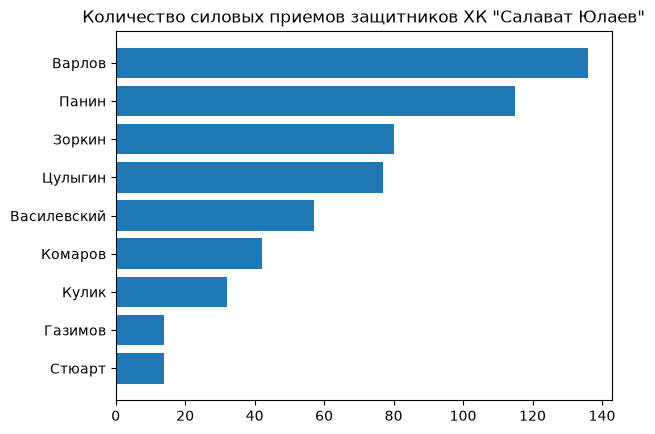

In [9]:
df_pressure = df_defenders[['Игрок','СПр']].sort_values(ascending=True, by='СПр')
plt.barh(df_pressure['Игрок'],df_pressure['СПр'])
plt.title('Количество силовых приемов защитников ХК "Салават Юлаев"')

# Общий вывод по каждому защитнику

|Игрок|Краткая характеристика|Выводы, тактика|
|-|--------|---|                                                              
|Варлов|Хороший игрок защиты, в зоне «Темные лошадки» (дешево, полезно)|Абсолютный лидер по физике. У него больше всех силовых. Отлично играет в "разрушение" атак соперника, ломает игру соперника у бортов. Если есть звено, которое нужно «запереть» в чужой зоне — Варлов хорошо справится с данной задачей|
|Панин|Лучший КПД (цена/качество)|Подтверждает статус опытного защитника: имеет высокий +/-, не боится силовой борьбы, физически мощный (2-е место по силовым).|
|Зоркин|Ключевой защитник|Имеет высокий показатель полезности с высоким игровым временем. Много силовых и блокированных. Разноплановый защитник, который может быть полезным как в обороне, так и в атаке|
|Стюарт|Ключевой атакующий защитник|Много блокирует, но силовую борьбу избегает. Помощник атакующим игрокам, при возврате в свою зону старается перекрывать броски соперников и играть на перехвате шайб. Защитник-созидатель, помощник. Можно назвать игрока "полузащитник", больше полезен в атаке, чем в обороне|
|Кулик|Хороший домосед|Хороший плюс-минус, среднее время на льду, небольшое количество силовых приемов, среднее количество заблокированных бросков|
|Василевский|Самоотверженный домосед|Лидер по блокированным броскам с отрывом. Среднее количество силовых. Он не является «физическим лидером», но и не избегает борьбы. Хороший защитник "домосед", строго играет в обороне, самоотверженная игра.|
|Цулыгин|Риск |Среднее количество силовых. Он пытается бороться, но делает это неэффективно (отсюда и минус в +/-). Проблема не в отсутствии желания, а в нехватке опыта|
|Комаров, Газимов |Игроки ротации|Низкое количество силовых. Играют неэффективно (+/- отрицательный). Имеет место, что в данной категории находятся молодые игроки, которые пытаются пробиться в основу и так же, как и в случае с Цулыгином имеют низкие показатели по причине нехватки опыта, уровня исполнения|